# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [48]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.13.0.3" 2026-10-24
OpenJDK Runtime Environment (build 21.0.13.0.3+1-1-24.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.13.0.3+1-1-24.04.1-Ubuntu, mixed mode, sharing)
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.13.0.3


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [49]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Overwriting Hello.java


In [50]:
!java Hello.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.13.0.3


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [51]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Overwriting TariffBefore.java


In [52]:
!java TariffBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [53]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Overwriting TariffAfter.java


In [54]:
!java TariffAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [55]:
!apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

PlantUML установлен


In [56]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


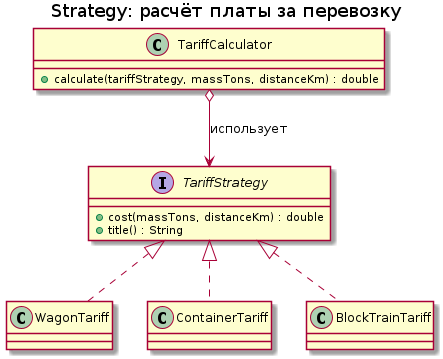

In [57]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** _(заполнить)_
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** _(заполнить)_
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** _(заполнить)_

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [58]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Overwriting FactoryBefore.java


In [59]:
!java FactoryBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [60]:
%%writefile FactoryAfter.java
import java.util.LinkedHashMap;
import java.util.Map;

public class FactoryAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {
        Map<String, ConsumerCreator> consumerCreators = new LinkedHashMap<>();
        consumerCreators.put("INDUSTRIAL", new IndustrialConsumerCreator());
        consumerCreators.put("RESIDENTIAL", new ResidentialConsumerCreator());
        consumerCreators.put("MUNICIPAL", new MunicipalConsumerCreator());

        System.out.println("--- Создание базовых типов потребителей электроэнергии ---");
        PowerConsumer industrial = consumerCreators.get("INDUSTRIAL").createConsumer(1500.0);
        PowerConsumer residential = consumerCreators.get("RESIDENTIAL").createConsumer(15.0);
        PowerConsumer municipal = consumerCreators.get("MUNICIPAL").createConsumer(250.0);

        System.out.println(industrial.description());
        System.out.println(residential.description());
        System.out.println(municipal.description());

        System.out.println("\n--- Характеризующие и структурные проверки ---");
        check("описание промышленного потребителя не пустое и содержит мощность",
                !industrial.description().isEmpty() && industrial.description().contains("1500.0"));
        check("описание бытового потребителя не пустое и содержит мощность",
                !residential.description().isEmpty() && residential.description().contains("15.0"));
        check("описание бюджетного потребителя не пустое и содержит мощность",
                !municipal.description().isEmpty() && municipal.description().contains("250.0"));

        check("создатель промышленных потребителей возвращает IndustrialConsumer",
                industrial instanceof IndustrialConsumer);
        check("создатель бытовых потребителей возвращает ResidentialConsumer",
                residential instanceof ResidentialConsumer);
        check("создатель бюджетных потребителей возвращает MunicipalConsumer",
                municipal instanceof MunicipalConsumer);

        System.out.println("\n--- Тест открытости/закрытости: добавление четвёртого типа (AgriculturalConsumer) ---");
        ConsumerCreator agriculturalCreator = new AgriculturalConsumerCreator();
        PowerConsumer agricultural = agriculturalCreator.createConsumer(420.0);
        System.out.println(agricultural.description());

        check("сельскохозяйственный потребитель создан новым создателем и работает корректно",
                agricultural instanceof AgriculturalConsumer
                && agricultural.allocatedPowerKw() == 420.0
                && agricultural.description().contains("420.0"));

        verifyAllPassed();
        System.out.println("\nВсе проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    static void verifyAllPassed() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
    }
}

interface PowerConsumer {
    String description();
    double allocatedPowerKw();
}

abstract class ConsumerCreator {
    public abstract PowerConsumer createConsumer(double allocatedPowerKw);
}


class IndustrialConsumer implements PowerConsumer {
    private final double allocatedPowerKw;

    IndustrialConsumer(double allocatedPowerKw) {
        this.allocatedPowerKw = allocatedPowerKw;
    }

    public double allocatedPowerKw() {
        return allocatedPowerKw;
    }

    public String description() {
        return "Промышленный потребитель: выделенная мощность " + allocatedPowerKw + " кВт, 1-я категория надёжности";
    }
}

class ResidentialConsumer implements PowerConsumer {
    private final double allocatedPowerKw;

    ResidentialConsumer(double allocatedPowerKw) {
        this.allocatedPowerKw = allocatedPowerKw;
    }

    public double allocatedPowerKw() {
        return allocatedPowerKw;
    }

    public String description() {
        return "Бытовой потребитель: выделенная мощность " + allocatedPowerKw + " кВт, 3-я категория надёжности";
    }
}

class MunicipalConsumer implements PowerConsumer {
    private final double allocatedPowerKw;

    MunicipalConsumer(double allocatedPowerKw) {
        this.allocatedPowerKw = allocatedPowerKw;
    }

    public double allocatedPowerKw() {
        return allocatedPowerKw;
    }

    public String description() {
        return "Бюджетное учреждение: выделенная мощность " + allocatedPowerKw + " кВт, 2-я категория надёжности";
    }
}

class AgriculturalConsumer implements PowerConsumer {
    private final double allocatedPowerKw;

    AgriculturalConsumer(double allocatedPowerKw) {
        this.allocatedPowerKw = allocatedPowerKw;
    }

    public double allocatedPowerKw() {
        return allocatedPowerKw;
    }

    public String description() {
        return "Сельскохозяйственный потребитель: выделенная мощность " + allocatedPowerKw + " кВт, сезонная нагрузка";
    }
}


class IndustrialConsumerCreator extends ConsumerCreator {
    public PowerConsumer createConsumer(double allocatedPowerKw) {
        return new IndustrialConsumer(allocatedPowerKw);
    }
}

class ResidentialConsumerCreator extends ConsumerCreator {
    public PowerConsumer createConsumer(double allocatedPowerKw) {
        return new ResidentialConsumer(allocatedPowerKw);
    }
}

class MunicipalConsumerCreator extends ConsumerCreator {
    public PowerConsumer createConsumer(double allocatedPowerKw) {
        return new MunicipalConsumer(allocatedPowerKw);
    }
}

/** Создатель для четвёртого типа потребителя. */
class AgriculturalConsumerCreator extends ConsumerCreator {
    public PowerConsumer createConsumer(double allocatedPowerKw) {
        return new AgriculturalConsumer(allocatedPowerKw);
    }
}


Overwriting FactoryAfter.java


In [61]:
!java FactoryAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Создание базовых типов потребителей электроэнергии ---
Промышленный потребитель: выделенная мощность 1500.0 кВт, 1-я категория надёжности
Бытовой потребитель: выделенная мощность 15.0 кВт, 3-я категория надёжности
Бюджетное учреждение: выделенная мощность 250.0 кВт, 2-я категория надёжности

--- Характеризующие и структурные проверки ---
[OK]   описание промышленного потребителя не пустое и содержит мощность
[OK]   описание бытового потребителя не пустое и содержит мощность
[OK]   описание бюджетного потребителя не пустое и содержит мощность
[OK]   создатель промышленных потребителей возвращает IndustrialConsumer
[OK]   создатель бытовых потребителей возвраща

In [62]:
%%writefile factory.puml
@startuml
title Factory Method: создание потребителя электроэнергии

interface PowerConsumer {
  +description() : String
  +allocatedPowerKw() : double
}

abstract class ConsumerCreator {
  +{abstract} createConsumer(allocatedPowerKw : double) : PowerConsumer
}

class IndustrialConsumer
class ResidentialConsumer
class MunicipalConsumer
class AgriculturalConsumer

class IndustrialConsumerCreator
class ResidentialConsumerCreator
class MunicipalConsumerCreator
class AgriculturalConsumerCreator

PowerConsumer <|.. IndustrialConsumer
PowerConsumer <|.. ResidentialConsumer
PowerConsumer <|.. MunicipalConsumer
PowerConsumer <|.. AgriculturalConsumer

ConsumerCreator <|-- IndustrialConsumerCreator
ConsumerCreator <|-- ResidentialConsumerCreator
ConsumerCreator <|-- MunicipalConsumerCreator
ConsumerCreator <|-- AgriculturalConsumerCreator

ConsumerCreator ..> PowerConsumer : создаёт
IndustrialConsumerCreator ..> IndustrialConsumer
ResidentialConsumerCreator ..> ResidentialConsumer
MunicipalConsumerCreator ..> MunicipalConsumer
AgriculturalConsumerCreator ..> AgriculturalConsumer
@enduml

Overwriting factory.puml


In [63]:
!apt-get update -qq && apt-get install -y -qq plantuml graphviz


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


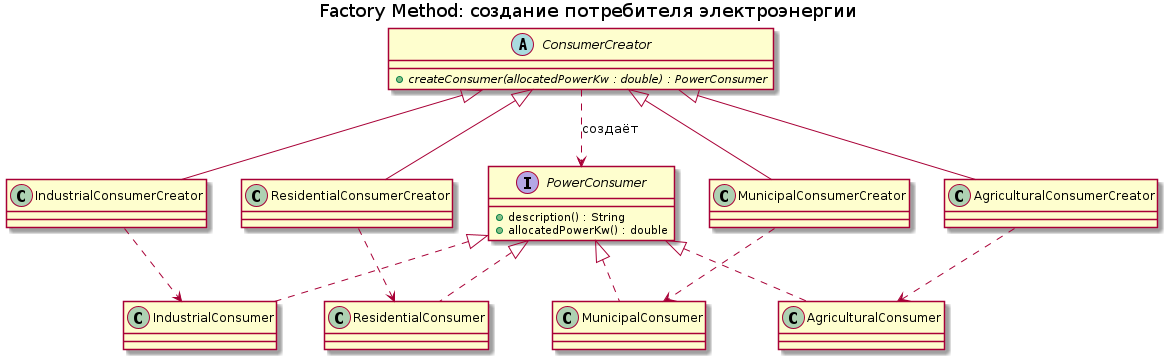

In [64]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): _(заполнить)_

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [65]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Overwriting ObserverBefore.java


In [66]:
!java ObserverBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [67]:
%%writefile ObserverAfter.java
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {
        EnergyDispatchCenter dispatchCenter = new EnergyDispatchCenter("ПС-110 кВ «Северная»");

        DispatchMimicBoard mimicBoard = new DispatchMimicBoard();
        EmergencyJournal emergencyJournal = new EmergencyJournal();
        RepairCrewAlert repairCrewAlert = new RepairCrewAlert();

        dispatchCenter.addListener(mimicBoard);
        dispatchCenter.addListener(emergencyJournal);
        dispatchCenter.addListener(repairCrewAlert);

        System.out.println("--- Событие 1: авария на линии Л-104 (порядок: Мнемосхема -> Журнал -> Вызов бригады) ---");
        dispatchCenter.reportOutage("КЗ на фидере Л-104");

        check("после первого события оперативный журнал получил ровно 1 запись",
                emergencyJournal.getRecords().size() == 1);
        check("все подписчики получили одно и то же событие (Л-104)",
                mimicBoard.getLastAlert().contains("Л-104")
                && emergencyJournal.getRecords().get(0).contains("Л-104")
                && repairCrewAlert.getDispatchedCount() == 1);

        System.out.println("\n--- Проверка отписки: отключаем вызов аварийной бригады ---");
        dispatchCenter.removeListener(repairCrewAlert);
        dispatchCenter.reportOutage("Отключение трансформатора Т-2");

        check("после отписки службы вызова бригад её счётчик вызовов не увеличился",
                repairCrewAlert.getDispatchedCount() == 1);
        check("оставшиеся подписчики получили второе событие (трансформатор Т-2)",
                emergencyJournal.getRecords().size() == 2
                && mimicBoard.getLastAlert().contains("Т-2"));

        System.out.println("\n--- Тест открытости/закрытости: добавление четвёртого наблюдателя (Телеметрия АСДУ) ---");
        ScadaTelemetry scadaTelemetry = new ScadaTelemetry();
        dispatchCenter.addListener(scadaTelemetry);
        dispatchCenter.reportOutage("Падение напряжения на шинах 10 кВ");

        check("четвёртый наблюдатель получил событие без изменения класса EnergyDispatchCenter",
                scadaTelemetry.getSentPackets().size() == 1
                && scadaTelemetry.getSentPackets().get(0).contains("ПС-110 кВ «Северная»"));

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println("\nВсе проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}


interface OutageListener {
    void onSubstationOutage(String substationName, String faultDescription);
}

class EnergyDispatchCenter {
    private final String substationName;
    private final List<OutageListener> listeners = new ArrayList<>();

    EnergyDispatchCenter(String substationName) {
        this.substationName = substationName;
    }

    void addListener(OutageListener listener) {
        listeners.add(listener);
    }

    void removeListener(OutageListener listener) {
        listeners.remove(listener);
    }

    void reportOutage(String faultDescription) {
        for (int i = 0; i < listeners.size(); i++) {
            listeners.get(i).onSubstationOutage(substationName, faultDescription);
        }
    }
}


class DispatchMimicBoard implements OutageListener {
    private String lastAlert = "";

    public void onSubstationOutage(String substationName, String faultDescription) {
        lastAlert = "[мнемосхема] ТРЕВОГА на " + substationName + ": " + faultDescription;
        System.out.println(lastAlert);
    }

    String getLastAlert() {
        return lastAlert;
    }
}

class EmergencyJournal implements OutageListener {
    private final List<String> records = new ArrayList<>();

    public void onSubstationOutage(String substationName, String faultDescription) {
        String entry = substationName + " — зафиксирована авария: " + faultDescription;
        records.add(entry);
        System.out.println("[журнал]     " + entry);
    }

    List<String> getRecords() {
        return records;
    }
}

class RepairCrewAlert implements OutageListener {
    private int dispatchedCount = 0;

    public void onSubstationOutage(String substationName, String faultDescription) {
        dispatchedCount++;
        System.out.println("[бригада]    Отправлен наряд ОВБ на " + substationName + " (" + faultDescription + ")");
    }

    int getDispatchedCount() {
        return dispatchedCount;
    }
}

class ScadaTelemetry implements OutageListener {
    private final List<String> sentPackets = new ArrayList<>();

    public void onSubstationOutage(String substationName, String faultDescription) {
        String packet = substationName + "|" + faultDescription;
        sentPackets.add(packet);
        System.out.println("[АСДУ]       Аварийный телесигнал передан в верхний уровень: " + packet);
    }

    List<String> getSentPackets() {
        return sentPackets;
    }
}


Overwriting ObserverAfter.java


In [68]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Событие 1: авария на линии Л-104 (порядок: Мнемосхема -> Журнал -> Вызов бригады) ---
[мнемосхема] ТРЕВОГА на ПС-110 кВ «Северная»: КЗ на фидере Л-104
[журнал]     ПС-110 кВ «Северная» — зафиксирована авария: КЗ на фидере Л-104
[бригада]    Отправлен наряд ОВБ на ПС-110 кВ «Северная» (КЗ на фидере Л-104)
[OK]   после первого события оперативный журнал получил ровно 1 запись
[OK]   все подписчики получили одно и то же событие (Л-104)

--- Проверка отписки: отключаем вызов аварийной бригады ---
[мнемосхема] ТРЕВОГА на ПС-110 кВ «Северная»: Отключение трансформатора Т-2
[журнал]     ПС-110 кВ «Северная» — зафиксирована авария: Отключение трансформатора Т-2
[OK] 

In [69]:
%%writefile observer.puml
@startuml
title Observer: оповещение об аварии на подстанции

interface OutageListener {
  +onSubstationOutage(substationName : String, faultDescription : String) : void
}

class EnergyDispatchCenter {
  -substationName : String
  -listeners : List<OutageListener>
  +addListener(listener : OutageListener) : void
  +removeListener(listener : OutageListener) : void
  +reportOutage(faultDescription : String) : void
}

class DispatchMimicBoard
class EmergencyJournal
class RepairCrewAlert
class ScadaTelemetry

EnergyDispatchCenter o--> "0..*" OutageListener : оповещает
OutageListener <|.. DispatchMimicBoard
OutageListener <|.. EmergencyJournal
OutageListener <|.. RepairCrewAlert
OutageListener <|.. ScadaTelemetry
@enduml

Overwriting observer.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


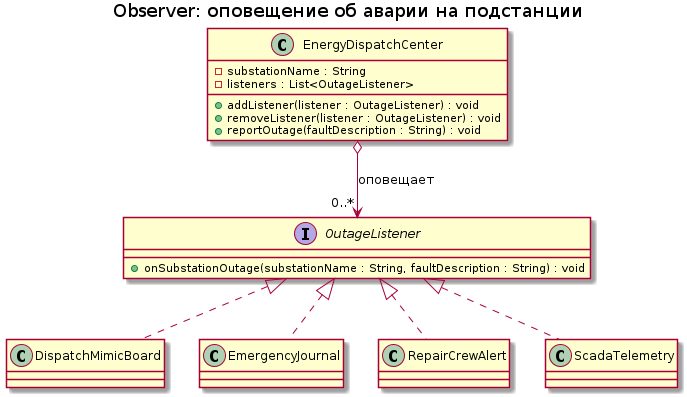

In [70]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка): _(заполнить)_

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy | Громоздкий метод с if/else, совмещающий выбор алгоритма и его вычисление | Новые алгоритмы расчёта (классы, реализующие общий интерфейс стратегии) | Увеличение числа классов; клиент должен знать о существовании стратегий для их выбора | Выбор тарифного плана (день, ночь, пик) в энергодиспетчерском пункте |
| Factory Method | Жёсткую привязку вызывающего кода к конкретным классам и ветвления при создании объектов | Новые типы создаваемых продуктов и соответствующие им классы-создатели | Необходимость создавать параллельную иерархию классов-создателей для каждого продукта | Создание карточек потребителей электроэнергии разных категорий (промышленный, бытовой, бюджетный) |
| Observer | Прямую зависимость источника событий от списка конкретных получателей | Новые обработчики (подписчики) событий без изменения класса-источника | Недетерминированный порядок вызовов, усложнение отладки потока выполнения, риск утечек памяти | Оповещение мнемосхемы, журнала, бригад и АСДУ об аварии на подстанции |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** _(заполнить)_
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** _(заполнить)_
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** _(заполнить)_
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** _(заполнить)_
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** _(заполнить)_

### 5.3 Три вывода по работе в целом

1. Создание объектов через фабричный метод делегирует инстанцирование подклассам, благодаря чему диспетчерский код работает только с общими интерфейсами (PowerConsumer, ConsumerCreator) и не привязан к конкретным классам через оператор new или ветвления if/switch. Фабрика излишня, если в системе гарантированно существует только один тип создаваемого объекта, логика его инициализации тривиальна и не предполагается её расширение в будущем.
2. Паттерн Observer снял жёсткую зависимость класса EnergyDispatchCenter от конкретных служб реагирования (мнемосхемы, журнала, вызова бригад), позволив подключать и отключать обработчики событий динамически во время работы. Однако появились новые архитектурные риски: неявный порядок уведомлений (зависит от порядка вызова addListener), риск каскадного сбоя (ошибка в одном подписчике может прервать цикл оповещения остальных) и утечки памяти из-за забытой отписки (removeListener).
3. …

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [71]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Кулай Никита Андреевич"  #@param {type:"string"}
Группа_исполнителя = "СИ-41"  #@param {type:"string"}
Номер_варианта = 12  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Кулай Никита Андреевич, группа СИ-41, вариант 12 |
| Дата и время отчёта (UTC) | 2026-11-17 06:32 |
| Версия Java | openjdk version "21.0.13.0.3" 2026-10-24 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 7 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 5 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |